In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import plotly.express as px

In [3]:
import joblib
import pickle

In [4]:
sns.set_style('darkgrid')

In [5]:
import warnings

# Customer Churn Analysis & Machine Learning Project.

Customer churn is the term used to describe when customers end their relationship or subscription with a company or service provider. Churn affects businesses’ revenue, growth, and customer loyalty. By studying churn and its related features, companies can create ways to keep existing customers, make them happier, and lower churn rates. They can also use predictive models to anticipate and prevent future churn, and take action to keep customers who are likely to leave.

The **Customer Churn Analysis & Machine Learning Project project** is devided into 4 stages, which are:

1. Data Cleaning
2. Exploratory Data Analysis (EDA) and Visualization
3. Machine-Learning predictive model development
4. Streamlit App development & model deployment.

This python script is the major section of the project whereby the stages above, with the exception of **Streamlit App development & model deployment** are accomplished. Three machine learning models( **Logistic Regression, Random Forest and XGBOOST**) are developed and the best model is saved and deployed using streamlit.


# About the Dataset used

Dataset used: **customer_churn_dataset-testing-master.csv** and **customer_churn_dataset-training-master.csv**, downloaded from Kaggle [here](https://www.kaggle.com/datasets/muhammadshahidazeem/customer-churn-dataset)

These datasets contains 12 feature columns. In detail, these are:

- CustomerID: A unique identifier for each customer
- Age: The age of the customer
- Gender: Gender of the customer
- Tenure: Duration in months for which a customer has been using the company's products or services
- Usage Frequency: Number of times that the customer has used the company’s services in the last month
- Support Calls: Number of calls that the customer has made to the customer support in the last month
- Payment Delay: Number of days that the customer has delayed their payment in the last month
- Subscription Type: Type of subscription the customer has choosen
- Contract Length: Duration of the contract that the customer has signed with the company
- Total Spend: Total amount of money the customer has spent on the company's products or services
- Last Interaction: Number of days since the last interaction that the customer had with the company
- Churn: Binary label indicating whether a customer has churned (1) or not (0)

# Import & Combine Datasets
- Dataset consists of two separate csv files, named training and testing.
- **The two datasets will be concatenated vertically and only split durring preprocessing.** 

In [6]:
Data = pd.read_csv('customer_churn_dataset-training-master.csv')

In [7]:
data = pd.read_csv('customer_churn_dataset-testing-master.csv')

In [8]:
Data.head(2)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0


In [9]:
data.head(2)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0


In [10]:
DATA = pd.concat([Data,data],axis = 0)

In [11]:
DATA.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [12]:
Data.shape,data.shape,DATA.shape

((440833, 12), (64374, 12), (505207, 12))

# Stage 1:  Data Cleaning

In [13]:
DATA.info()

<class 'pandas.DataFrame'>
Index: 505207 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         505206 non-null  float64
 1   Age                505206 non-null  float64
 2   Gender             505206 non-null  str    
 3   Tenure             505206 non-null  float64
 4   Usage Frequency    505206 non-null  float64
 5   Support Calls      505206 non-null  float64
 6   Payment Delay      505206 non-null  float64
 7   Subscription Type  505206 non-null  str    
 8   Contract Length    505206 non-null  str    
 9   Total Spend        505206 non-null  float64
 10  Last Interaction   505206 non-null  float64
 11  Churn              505206 non-null  float64
dtypes: float64(9), str(3)
memory usage: 59.4 MB


In [14]:
DATA.isnull().sum()

CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

## Removing the NaN values

In [15]:
DATA[DATA['Age'].isnull()]

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
DATA = DATA.dropna(how = 'all',axis = 0).reset_index(drop = True)

In [17]:
DATA.iloc[199295]

CustomerID           204107.0
Age                      36.0
Gender                 Female
Tenure                   46.0
Usage Frequency          24.0
Support Calls             7.0
Payment Delay             1.0
Subscription Type       Basic
Contract Length       Monthly
Total Spend             118.9
Last Interaction         27.0
Churn                     1.0
Name: 199295, dtype: object

In [18]:
DATA.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

# Stage 2:  Data Exploration and Vitualisation

In [19]:
df = DATA

In [20]:
round(df.drop(['CustomerID','Churn'],axis = 1).describe(),2)

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
count,505206.00,505206.00,505206.00,505206.00,505206.00,505206.00,505206.00
mean,39.70,31.35,15.71,3.83,13.50,620.07,14.61
std,12.67,17.24,8.62,3.13,8.45,245.32,8.61
min,18.00,1.00,1.00,0.00,0.00,100.00,1.00
25%,29.00,16.00,8.00,1.00,6.00,446.00,7.00
50%,40.00,32.00,16.00,3.00,13.00,648.90,14.00
75%,49.00,46.00,23.00,6.00,20.00,824.00,22.00
max,65.00,60.00,30.00,10.00,30.00,1000.00,30.00


# Histogram Distribustions of numerical features by 'Churn'

In [21]:
df_num = df.select_dtypes(include  = 'number').drop(['CustomerID'],axis = 1)

C:\Users\KENNETH\AppData\Local\Temp\ipykernel_8912\2912977738.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0,2].legend(loc = 'upper right',bbox_to_anchor = (1.3,1),title = 'Churn')


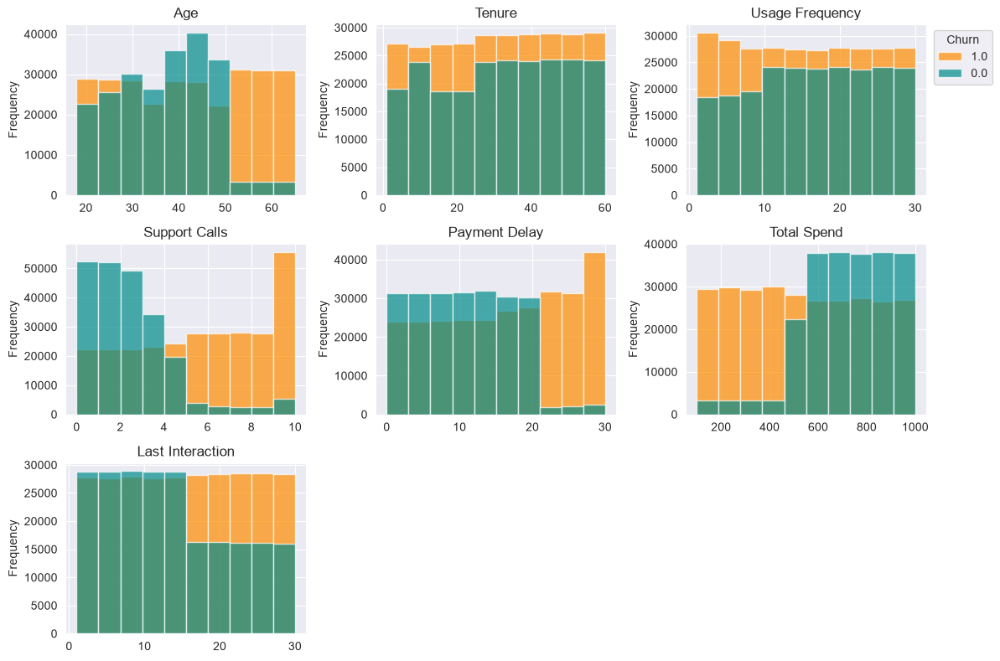

In [22]:
fig, ax = plt.subplots(3,3,figsize = (12,8))

for i, axes,feat in zip(range(7),ax.ravel(),df_num.drop(['Churn'],axis = 1).columns):
    axes.hist(x = df_num[df_num['Churn']==1][feat],label = 1.0,color = 'darkorange',alpha = 0.7)
    axes.hist(x = df_num[df_num['Churn']==0][feat] ,label = 0.0, color = 'darkcyan',alpha = 0.7)
    axes.set_title(feat)
    axes.set_ylabel('Frequency')
    ax[0,2].legend(loc = 'upper right',bbox_to_anchor = (1.3,1),title = 'Churn')
    
fig.delaxes(ax[2,1]) 
fig.delaxes(ax[2,2]) 
plt.tight_layout()

- Support calls past 4 days, Age geater than 50 years, Payment Delays past 20 days and Total Spend below 500, are overwhelmingly churners.
- The last interaction days past 17 days consist of approximatley one-third more churners as comapared to Non-Churners.
- Ternure and Usage Frequency appear to have similar distributions on both Churners and Non-Churners.

**Percentage Churn of customers over the age of 50**

In [51]:
round(df[df['Age']>=50]['Churn'].value_counts()/len(df)*100,0)

Churn
1.0    19.0
0.0     4.0
Name: count, dtype: float64

- Customers over the Age of 50 contribute 23% to the business, with 19% ending up Churning and 4% not churning.

**Percentage churn of Support calls greater or equal to 4 days**

In [26]:
round(df[df['Support Calls']>=4]['Churn'].value_counts()/len(df)*100,0)

Churn
1.0    38.0
0.0     7.0
Name: count, dtype: float64

- Customers who make 4 or more support calls a month contribute 45% to the business, with 38% ending up churning while 7% remain with the business.

**Percentage Total Spend less than $500 by Churn**

In [54]:
round(df[df['Total Spend']<500]['Churn'].value_counts()/len(df)*100,0)

Churn
1.0    26.0
0.0     3.0
Name: count, dtype: float64

- Customers with a Total Spend less than $500 contribute 29% to the business, with 26% ending up churning and only 3% remaining with the business.

**Percentage churn of Payment Delay past 20 days**

In [30]:
round(df[df['Payment Delay']>=20]['Churn'].value_counts()/len(df)*100,0)

Churn
1.0    23.0
0.0     3.0
Name: count, dtype: float64

- Customers who delay payments by more 20 days or more, contribute 26% to the business, with 23% churners and only 3% non churners.

**Percentage churn of Last Interaction past 17 days**

In [55]:
round(df[df['Last Interaction']>=17]['Churn'].value_counts()/len(df)*100,0)

Churn
1.0    24.0
0.0    14.0
Name: count, dtype: float64

- Customers who do not interact with the business for 17 or more days in a month contribute to 38% to the business,
- with 24% ending up churning while 14% remain with the business.

## Box Plots Distributions of the Numerical features by Churn

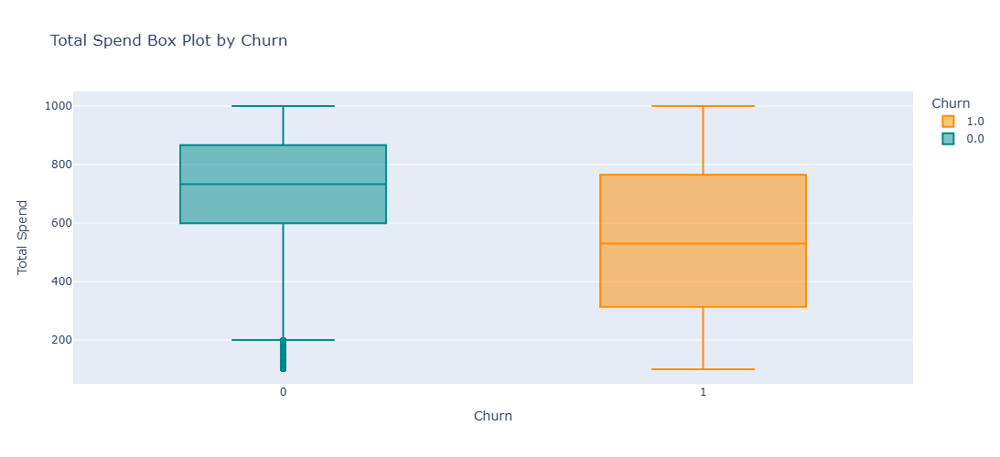

In [33]:
px.box(df_num,x = 'Churn',y = 'Total Spend',
       height = 500,width = 900,
       color = 'Churn',
       color_discrete_map = {1.0:'darkorange',0.0:'darkcyan'},
       title='Total Spend Box Plot by Churn')

- Its clear that customers who churn appear to have less Total Spend than Non-Churners.

In [34]:
df[(df['Total Spend']<=200) & (df['Churn']==0)]['CustomerID'].count()

np.int64(3617)

In [35]:
df.head(3)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0


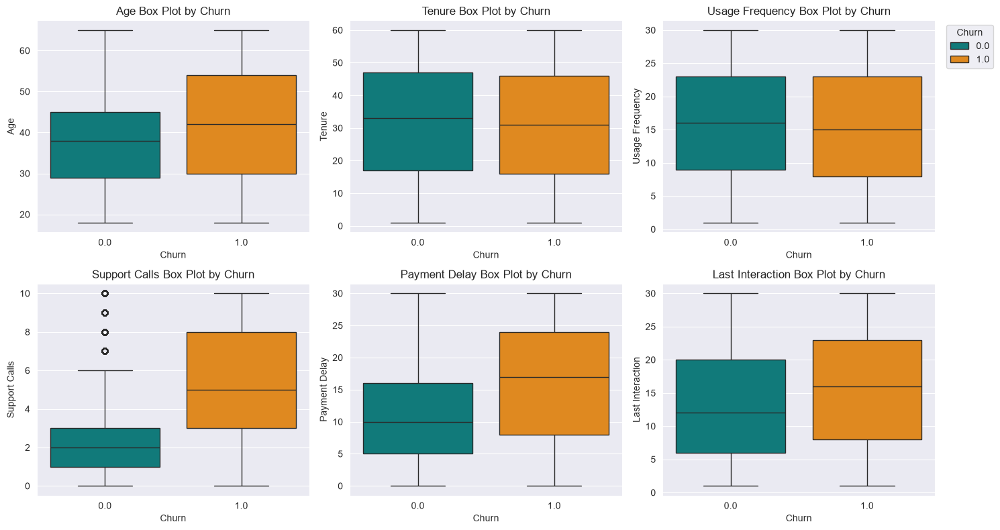

In [36]:
fig, ax = plt.subplots(2,3,figsize = (15,8))

for i, axes,feat in zip(range(6),ax.ravel(),df_num.drop(['Churn','Total Spend'],axis = 1).columns):
    
    if i==2:
        axes = sns.boxplot(data = df_num,y = feat,x = 'Churn',
                           hue = 'Churn',palette = {1.0:'darkorange',0.0:'darkcyan'},
                           ax = axes,legend = True)
        axes.legend(loc = 'upper right',bbox_to_anchor = (1.23,1),title = 'Churn')
        axes.set_title(feat+' Box Plot by Churn')
        
    else:
        axes = sns.boxplot(data = df_num,y = feat,x = 'Churn',
                           hue = 'Churn',palette = {1.0:'darkorange',0.0:'darkcyan'},
                           ax = axes, legend = False)
        axes.set_title(feat+' Box Plot by Churn')

    plt.tight_layout()  

- There is a clear overlap in the distribustions of the churners and Non-churners in the Support calls, Payment Delay and Age.
- 75% of churners in the support calls make more than 3 to 10 calls, whereas 75% of Non-Churners make less than 3 support calls, with few outliers making 6 to 10 suppport calls.
- More than 50% of Churners dalay the payments by over 17 days, whereas 75% of Non-churners are below 17 days.
- Customers over the age of 45 are more likely to churn, whereas those below the age of 45 have equal chance of churning or not-churning.
- Tenure, Last Interaction and Usage Frequency appear to have approximatley same distributions of Churners and Non-Churners. 

## Distribustions of categorical features features by 'Churn'

In [37]:
df.head(2)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0


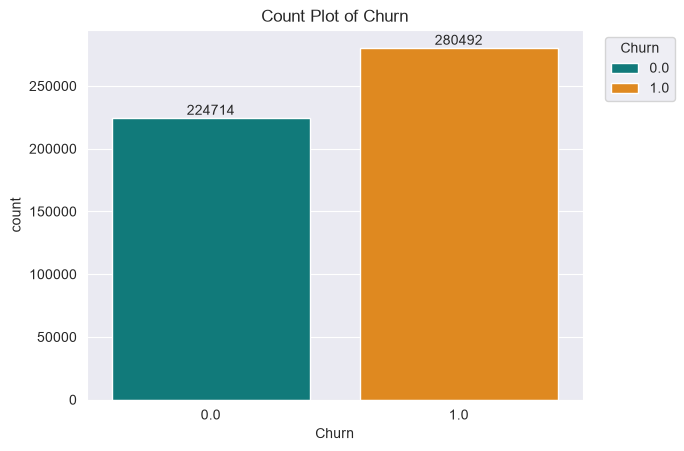

In [38]:
ax = sns.countplot(data = df,x = 'Churn',hue = 'Churn',palette = {1.0:'darkorange',0.0:'darkcyan'})
plt.legend(loc = 'upper right',bbox_to_anchor = (1.2,1),title = 'Churn')
plt.title('Count Plot of Churn')

for container in ax.containers:
    ax.bar_label(container)

In [39]:
round((df['Churn'].value_counts()/len(df))*100,0)

Churn
1.0    56.0
0.0    44.0
Name: count, dtype: float64

- The dataset consist of 55.52% samples of churners(1) as compared to the 44.48% Non-churners(0).
- This class imbalance should be adressed during model training.

In [40]:
df_cat = pd.concat([df.select_dtypes(include = 'string'),df['Churn']],axis = 1)

In [41]:
df_cat.head(2)

,Gender,Subscription Type,Contract Length,Churn
0,Female,Standard,Annual,1.0
1,Female,Basic,Monthly,1.0


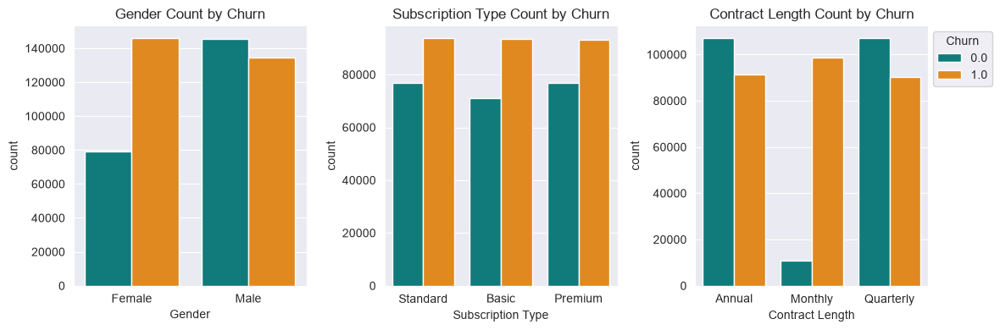

In [42]:
fig, ax = plt.subplots(1,3,figsize = (12,4))

for i, axes,feat in zip(range(3),ax.ravel(),df_cat.drop(['Churn'],axis = 1).columns):
    
    if i==2:
        axes = sns.countplot(data = df_cat,x = feat,hue = 'Churn',palette = {1.0:'darkorange',0.0:'darkcyan'},ax = axes,legend=True)
        axes.legend(loc = 'upper right',bbox_to_anchor = (1.3,1),title = 'Churn')
        axes.set_title(feat+' Count by Churn')
        
    else:
        axes = sns.countplot(data = df_cat,x = feat,hue = 'Churn',palette = {1.0:'darkorange',0.0:'darkcyan'},ax = axes,legend=False)
        axes.set_title(feat+' Count by Churn')

    plt.tight_layout()    

**Percentage Churn by Contract Length**

In [43]:
round(df.groupby(['Contract Length'])['Churn'].value_counts()/len(df)*100,0)

Contract Length  Churn
Annual           0.0      21.0
                 1.0      18.0
Monthly          1.0      20.0
                 0.0       2.0
Quarterly        0.0      21.0
                 1.0      18.0
Name: count, dtype: float64

- Monthly contract customers contribute 22% to the business; with the percentage churn of 20% and only 2% non churn.
- Both Annual and Quartely contract customers contribute 39% each to the business, with 18% percentage churn and 21% non churn.

**Percentage Churn by Gender**

In [64]:
round(df.groupby(['Gender'])['Churn'].value_counts()/len(df)*100,0)

Gender  Churn
Female  1.0      29.0
        0.0      16.0
Male    0.0      29.0
        1.0      27.0
Name: count, dtype: float64

- The Female gender customers contribute approximatley 45% to the business, with 29% percentage churn and 16% non churn.
- The Male gender customers contribute approximatley 56% to the business, with 27% percentage churn and 29% non churn.

**Percentage Churn by Subscription Type**

In [45]:
round(df.groupby(['Subscription Type'])['Churn'].value_counts()/len(df)*100,0)

Subscription Type  Churn
Basic              1.0      19.0
                   0.0      14.0
Premium            1.0      18.0
                   0.0      15.0
Standard           1.0      19.0
                   0.0      15.0
Name: count, dtype: float64

- The percentage churn by Subscription Type appears to be approximatley equivalent across all the subscription types.
- Basic and Standard subcriptions churn at 19% while Premium churn at 18%.
- Standard and Premium subsciptions have 15% non churn customers while Basic have 14%.

## Checking colinearity of the Numeric features

In [46]:
df_num.drop(['Churn'],axis = 1).corr()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
Age,1.000000,-0.010078,-0.013551,0.146790,0.060569,-0.078679,0.027472
Tenure,-0.010078,1.000000,-0.020686,-0.013381,-0.004400,0.015810,-0.004726
Usage Frequency,-0.013551,-0.020686,1.000000,-0.025947,-0.012667,0.019573,-0.006358
Support Calls,0.146790,-0.013381,-0.025947,1.000000,0.176038,-0.206566,0.074070
Payment Delay,0.060569,-0.004400,-0.012667,0.176038,1.000000,-0.125975,0.041767
Total Spend,-0.078679,0.015810,0.019573,-0.206566,-0.125975,1.000000,-0.054560
Last Interaction,0.027472,-0.004726,-0.006358,0.074070,0.041767,-0.054560,1.000000


<Axes: >

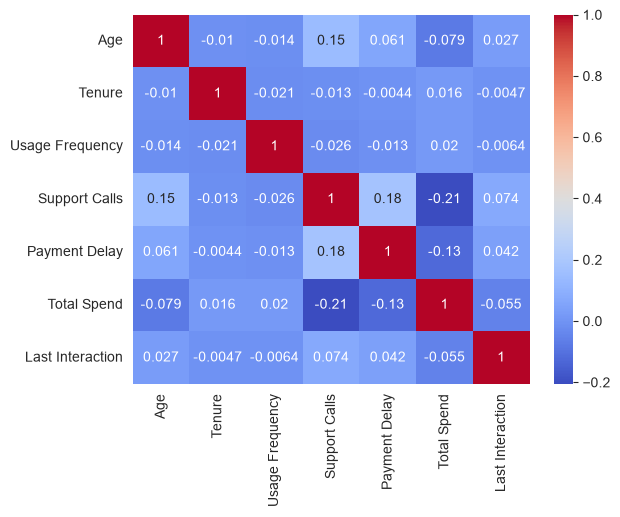

In [47]:
sns.heatmap(df_num.drop(['Churn'],axis = 1).corr(),cmap = 'coolwarm',annot = True)

**There appears to be no multicolinearity in the Churn predicting features**

## Numerical features correlations to the 'Churn'

In [48]:
df_num.corr()['Churn']

Age                 0.191224
Tenure             -0.021308
Usage Frequency    -0.053263
Support Calls       0.516283
Payment Delay       0.329785
Total Spend        -0.369682
Last Interaction    0.127150
Churn               1.000000
Name: Churn, dtype: float64

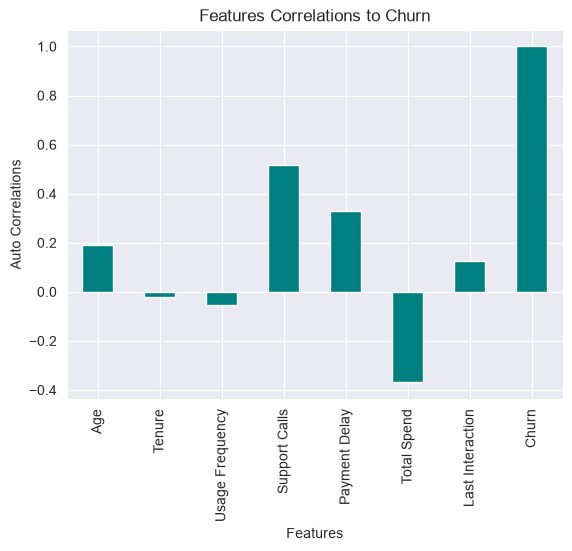

In [49]:
df_num.corr()['Churn'].plot(kind = 'bar', color = 'teal')
plt.title('Features Correlations to Churn')
plt.xlabel('Features')
plt.ylabel('Auto Correlations')
plt.xticks(rotation = 90)
plt.show()

- The Support Calls, Total Spend and Payment delays appear most correlated to Churn and therefore good candidates for predicting churn.

# Stage 3:  Machine-Learning predictive models development.

**Rearange the columns based on datatypes and convert floats to integers**

In [39]:
df = pd.concat([df.select_dtypes(include = 'string'), df.select_dtypes(include = 'number').astype('int64')],axis = 1).reset_index(drop = True)  

In [40]:
df.head(3)

,Gender,Subscription Type,Contract Length,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
0,Female,Standard,Annual,2,30,39,14,5,18,932,17,1
1,Female,Basic,Monthly,3,65,49,1,10,8,557,6,1
2,Female,Basic,Quarterly,4,55,14,4,6,18,185,3,1


**Drop the CustomerID it will not be used in modelling**

In [41]:
df = df.drop(['CustomerID'],axis = 1)

In [42]:
df.tail(2)

,Gender,Subscription Type,Contract Length,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
505204,Female,Standard,Monthly,50,18,19,7,22,540,13,1
505205,Female,Standard,Monthly,52,45,15,9,25,696,22,1


# 3.1 Data Preprocessing 

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split 

**Split data into training and test sets**

In [45]:
X = df.drop(['Churn'],axis =1)
y = df['Churn']

In [46]:
X_train,X_test,y_train,y_test = train_test_split(X,y, stratify = y, random_state = 101 ,test_size = 0.3)

**Categorical columns**

In [47]:
categories = X_train.select_dtypes(include = 'string').columns

In [48]:
categories

Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='str')

**Numerical Columns**

In [49]:
numeric = X_train.select_dtypes(include = 'number').columns

In [50]:
numeric

Index(['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction'],
      dtype='str')

**OneHotEncoder for logistict regression. ( drop first column to avoid perfect multicolinearity)**

In [51]:
logreg_encoder = OneHotEncoder(drop ='first',sparse_output = False)

In [52]:
logreg_preprocessor = ColumnTransformer(transformers = [('Categorical', logreg_encoder, categories),('Numerical',StandardScaler(), numeric)])

In [53]:
logreg_preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Categorical', ...), ('Numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

**OneHotEncoder for XGBOOST Classifier (multicoliearity does not affect trees splitting)**

In [54]:
xgb_encoder = OneHotEncoder(drop = None, sparse_output = False)

In [55]:
xgb_preprocessor = ColumnTransformer(transformers= [('Categorical', xgb_encoder ,categories)],remainder = 'passthrough')

In [56]:
xgb_preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name`

**OneHotEncoder for Random Forest Classifier (multicoliearity does not affect trees splitting)**

In [57]:
rfc_encoder = OneHotEncoder(drop = None, sparse_output = False)

In [58]:
rfc_preprocessor = ColumnTransformer(transformers= [('Categorical', rfc_encoder ,categories)],remainder = 'passthrough')

In [59]:
rfc_preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name`

# 3.2 Modelling 

# 3.2.1 Logistic Regression 

In [62]:
from sklearn.linear_model import LogisticRegression

In [63]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [64]:
from sklearn.pipeline import Pipeline

**Logistic regression Pipeline**

In [135]:
logreg_pipeline = Pipeline([
    ('logreg_preprocessor', logreg_preprocessor),
    ('logreg', LogisticRegression(solver = 'saga', max_iter = 1000, random_state = 101, class_weight = 'balanced'))
])


**Logistic Regression Hyperparameters search space**

In [136]:
logreg_param_grid = {
    'logreg__C': [0.01, 0.1, 1.0],         # Regularisation strength 
}

**Cross-validation gridsearch**

In [137]:

logreg_grid = GridSearchCV(
    estimator = logreg_pipeline,
    param_grid = logreg_param_grid,
    cv = StratifiedKFold(n_splits = 3, shuffle = True, random_state = 101),
    scoring = 'accuracy',
    verbose = 3
)

**Model fitting**

In [ ]:
logreg_grid.fit(X_train,y_train)

In [139]:
print(f"\n Best Regularisation Strength Hyperparameter: {logreg_grid.best_params_}\n")
print(f" Best Cross-Validation Accuracy Score: {logreg_grid.best_score_:.4f}")

Best Regularisation Strength Hyperparameter: {'logreg__C': 1.0}
Best Cross-Validation Accuracy Score: 0.8422


### Model Evaluation 

In [80]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score

In [254]:
best_logreg_model = logreg_grid.best_estimator_    # Extract the best fitted Logistic Regression Pipeline Model from the GridSearch

In [255]:
y_pred = best_logreg_model.predict(X_test)

In [256]:
accuracy = accuracy_score(y_test,y_pred)
c_matrix = confusion_matrix(y_test, y_pred)
c_report = classification_report(y_test, y_pred,digits = 4)

In [257]:
print(' Accuaracy Score: {}\n\n Confusion Matrix:\n\n {}\n\n Classification Report:\n\n {}'.format(round(accuracy,4),c_matrix,c_report))

 Accuaracy Score: 0.8417

 Confusion Matrix:

 [[58536  8878]
 [15114 69034]]

 Classification Report:

               precision    recall  f1-score   support

           0     0.7948    0.8683    0.8299     67414
           1     0.8861    0.8204    0.8520     84148

    accuracy                         0.8417    151562
   macro avg     0.8404    0.8443    0.8409    151562
weighted avg     0.8455    0.8417    0.8422    151562



# 3.2.2 Random Forest Classifier 

In [61]:
from sklearn.ensemble import RandomForestClassifier

**Random Forest Pipeline**

In [70]:
rfc_pipeline = Pipeline([('rfc_preprocessor',rfc_preprocessor),('rfc', RandomForestClassifier(class_weight = 'balanced', min_samples_leaf = 20))])

**Random Forest Classifier Hyperparameters search space**

In [71]:
rfc_param_grid = {
    "rfc__n_estimators": [100,200],
    "rfc__max_depth": [6,8,10],
    "rfc__max_features": [4,6] }

**Cross-Validation Gridsearch**

In [72]:
rfc_grid = GridSearchCV(estimator = rfc_pipeline,
                        param_grid = rfc_param_grid,
                        cv = StratifiedKFold(n_splits = 3,
                        shuffle = True,
                        random_state = 101),
                        scoring = 'accuracy',
                        verbose = 3 )

**Model fitting**

In [73]:
rfc_grid.fit(X_train,y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
[CV 1/3] END rfc__max_depth=6, rfc__max_features=4, rfc__n_estimators=100;, score=0.918 total time=  33.6s
[CV 2/3] END rfc__max_depth=6, rfc__max_features=4, rfc__n_estimators=100;, score=0.920 total time=  29.5s
[CV 3/3] END rfc__max_depth=6, rfc__max_features=4, rfc__n_estimators=100;, score=0.917 total time=  29.6s
[CV 1/3] END rfc__max_depth=6, rfc__max_features=4, rfc__n_estimators=200;, score=0.918 total time=  59.3s
[CV 2/3] END rfc__max_depth=6, rfc__max_features=4, rfc__n_estimators=200;, score=0.917 total time=  58.0s
[CV 3/3] END rfc__max_depth=6, rfc__max_features=4, rfc__n_estimators=200;, score=0.917 total time=  56.3s
[CV 1/3] END rfc__max_depth=6, rfc__max_features=6, rfc__n_estimators=100;, score=0.920 total time=  37.0s
[CV 2/3] END rfc__max_depth=6, rfc__max_features=6, rfc__n_estimators=100;, score=0.923 total time=  35.3s
[CV 3/3] END rfc__max_depth=6, rfc__max_features=6, rfc__n_estimators=100;, score=0

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...es_leaf=20))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'rfc__max_depth': [6, 8, ...], 'rfc__max_features': [4, 6], 'rfc__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto

In [75]:
print(f"\n Best Hyper-Parameters: {rfc_grid.best_params_}\n")
print(f" Best Cross-Validation Accuracy Score: {rfc_grid.best_score_:.4f}")


 Best Hyper-Parameters: {'rfc__max_depth': 10, 'rfc__max_features': 6, 'rfc__n_estimators': 100}

 Best Cross-Validation Accuracy Score: 0.9326


## Random Forest Model Evaluation

In [76]:
best_rfc_model = rfc_grid.best_estimator_

In [78]:
y_pred = best_rfc_model.predict(X_test)

In [81]:
c_matrix = confusion_matrix(y_test, y_pred)
c_report = classification_report(y_test, y_pred,digits=4)
Accuracy = accuracy_score(y_test, y_pred)

In [83]:
print(' Accuaracy Score: {}\n\n Confusion Matrix:\n\n {}\n\n Classification Report:\n\n {}'.format(round(Accuracy,4),c_matrix,c_report))

 Accuaracy Score: 0.9313

 Confusion Matrix:

 [[57849  9565]
 [  846 83302]]

 Classification Report:

               precision    recall  f1-score   support

           0     0.9856    0.8581    0.9174     67414
           1     0.8970    0.9899    0.9412     84148

    accuracy                         0.9313    151562
   macro avg     0.9413    0.9240    0.9293    151562
weighted avg     0.9364    0.9313    0.9306    151562



# 3.2.3 XGBOOST Classifier

In [227]:
from xgboost import XGBClassifier

**Ratio of churn(1) to the Not-Churn(0)**

In [228]:
ratio = round((df['Churn'] == 0).sum()/(df['Churn'] == 1).sum(),3)

In [229]:
print(ratio)

0.801


**XGBOOST Classifier Pipeline**

In [ ]:
xgb_pipeline = Pipeline([('xgb_preprocessor', xgb_preprocessor), 
                         ('xgb', XGBClassifier(scale_pos_weight = ratio, eval_metric = 'logloss'))])

**XGBOOST Classifier Hyperparameters search space**

In [243]:
xgb_param_grid = {
    'xgb__max_depth': [6,7],
    'xgb__n_estimators': [100,200,300],
    'xgb__learning_rate':[0.01,0.05,0.1]}

**Cross-Validation Gridsearch**

In [246]:
xgb_grid = GridSearchCV(estimator = xgb_pipeline,
                        param_grid = xgb_param_grid,
                        cv = StratifiedKFold(n_splits = 3, shuffle = True, random_state = 101),
                        scoring = 'accuracy',
                       verbose = 3)


**Model fitting**

In [247]:
xgb_grid.fit(X_train,y_train)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV 1/3] END xgb__learning_rate=0.01, xgb__max_depth=6, xgb__n_estimators=100;, score=0.920 total time=   3.4s
[CV 2/3] END xgb__learning_rate=0.01, xgb__max_depth=6, xgb__n_estimators=100;, score=0.922 total time=   3.5s
[CV 3/3] END xgb__learning_rate=0.01, xgb__max_depth=6, xgb__n_estimators=100;, score=0.919 total time=   3.3s
[CV 1/3] END xgb__learning_rate=0.01, xgb__max_depth=6, xgb__n_estimators=200;, score=0.924 total time=   5.9s
[CV 2/3] END xgb__learning_rate=0.01, xgb__max_depth=6, xgb__n_estimators=200;, score=0.926 total time=   6.0s
[CV 3/3] END xgb__learning_rate=0.01, xgb__max_depth=6, xgb__n_estimators=200;, score=0.923 total time=   5.7s
[CV 1/3] END xgb__learning_rate=0.01, xgb__max_depth=6, xgb__n_estimators=300;, score=0.925 total time=   8.5s
[CV 2/3] END xgb__learning_rate=0.01, xgb__max_depth=6, xgb__n_estimators=300;, score=0.927 total time=  13.8s
[CV 3/3] END xgb__learning_rate=0.01, xgb__max_dept

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'xgb__learning_rate': [0.01, 0.05, ...], 'xgb__max_depth': [6, 7], 'xgb__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:

In [251]:
print(f"\n Best Hyper-Parameters: {xgb_grid.best_params_}\n")
print(f" Best Cross-Validation Accuracy Score: {xgb_grid.best_score_:.4f}")

Best Hyper-Parameters: {'xgb__learning_rate': 0.05, 'xgb__max_depth': 7, 'xgb__n_estimators': 200}
Best Cross-Validation Accuracy Score: 0.9342


## XGBOOST Model Evaluation

In [252]:
best_xgb_model = xgb_grid.best_estimator_ # Extract the best fitted XGBOOST Pipeline from the GridSearch

In [259]:
y_pred = best_xgb_model.predict(X_test)

In [260]:
c_matrix = confusion_matrix(y_test, y_pred)
c_report = classification_report(y_test, y_pred,digits=4)
Accuracy = accuracy_score(y_test, y_pred)

In [261]:
print(' Accuracy Score: {:.4f}\n\n Confusion Matrix:\n\n {}\n\n Classification Report:\n\n {}'.format(Accuracy,c_matrix,c_report))

 Accuracy Score: 0.9333

 Confusion Matrix:

 [[57802  9612]
 [  502 83646]]

 Classification Report:

               precision    recall  f1-score   support

           0     0.9914    0.8574    0.9196     67414
           1     0.8969    0.9940    0.9430     84148

    accuracy                         0.9333    151562
   macro avg     0.9442    0.9257    0.9313    151562
weighted avg     0.9389    0.9333    0.9326    151562



# 3.3 Save the best Model for use in Streamlit App development

- Since our model's purpose is to detect the churn(1) :
- our best model should have the best recall in predict the churn(1), while preserving a good overall accuracy score in predicting both churn(1 and 0).
- The lowest perfoming model is the Logistic Regression with accuaracy score of 0.8417 and Churn(1) recall of 0.8204.
- The competing models are the Random Forest and the XGBOOST Classifiers.
- The XGBOOST Classifier has the best churn(1) recall of 0.9940, with overall accuracy score of 0.9333, and only misclassifies 502 samples out of the 84148 churn(1) testing samples, 
- Whereas the Random Forest Classifier has 0.9899 as the churn(1) recall, with overall accuracy score of 0.9313, and misclassiies 846 churn(1) samples out of 84148 Churn(1) testing samples.
- Based on the accuracy score and recall the XGBOOST Classifier is the best model.

In [262]:
import joblib

In [263]:
best_model = best_xgb_model

In [264]:
 joblib.dump(best_model,'XGBOOST_Churn_Model.pkl')

['XGBOOST_Churn_Model.pkl']

## Feature Importances plot

In [275]:
xgb = best_xgb_model.named_steps.xgb

In [276]:
feature_importances = xgb.feature_importances_

In [278]:
feature_importances

array([0.10113256, 0.        , 0.00571279, 0.00182344, 0.00171368,
       0.0031165 , 0.28315887, 0.00191742, 0.05308017, 0.01025934,
       0.00423398, 0.35300544, 0.07746881, 0.0972377 , 0.00613933],
      dtype=float32)

In [339]:
X_train.head()

,Gender,Subscription Type,Contract Length,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
349360,Male,Standard,Annual,45,21,14,1,9,863,20
137985,Female,Premium,Monthly,64,57,12,2,7,821,25
325957,Female,Standard,Annual,46,26,8,2,9,565,14
326614,Male,Basic,Quarterly,29,49,1,2,10,547,7
130242,Male,Standard,Quarterly,59,25,19,0,12,702,25


In [283]:
encoded_features = ['Gender(Female)','Gender(Male)',
                    'Subscription Type(Basic)','Subscription Type(Premium)','Subscription Type(Standard)', 
                     'Contract Length(Annual)','Contract Length(Monthly)','Contract Length(Quarterly)',
                    'Age','Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']


In [316]:
px_df = pd.DataFrame(feature_importances,encoded_features).reset_index().rename(columns = {'index':'features',0:'importances'})

In [337]:
px_df.head(3)

,features,importances
0,Gender(Female),0.101133
1,Gender(Male),0.000000
2,Subscription Type(Basic),0.005713


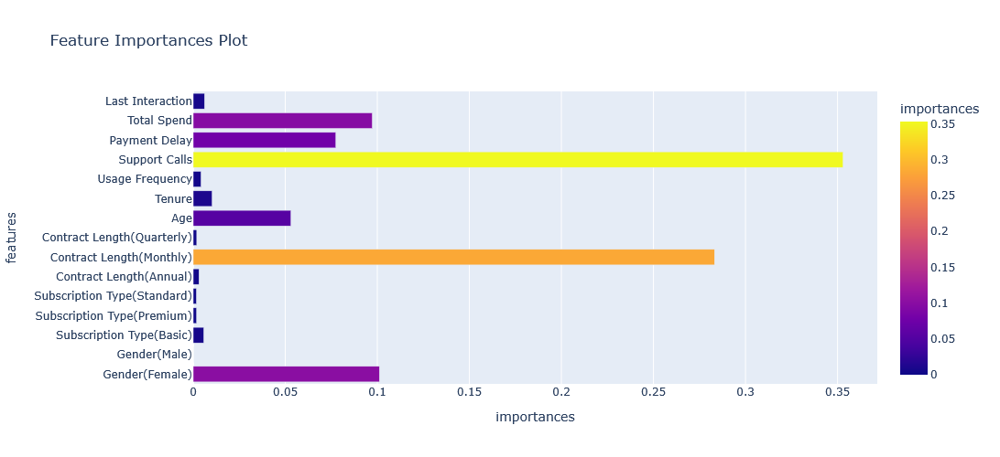

In [332]:
px.bar(px_df,x = 'importances',y = 'features',height = 500, width = 1000,
       color = 'importances',
       color_discrete_sequence = px.colors.qualitative.Vivid,
       hover_name = 'features',
      title = 'Feature Importances Plot')

## Create and Save Feature Importances DataFrame as csv file for use in streamlit App development

In [334]:
df_importances = pd.DataFrame(data = feature_importances.reshape(1,15),columns = encoded_features)

In [335]:
df_importances.to_csv('impotances_dataframe.csv',index=False)

In [336]:
pd.read_csv('impotances_dataframe.csv')

,Gender(Female),Gender(Male),Subscription Type(Basic),Subscription Type(Premium),Subscription Type(Standard),Contract Length(Annual),Contract Length(Monthly),Contract Length(Quarterly),Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
0,0.101133,0.0,0.005713,0.001823,0.001714,0.003117,0.283159,0.001917,0.05308,0.010259,0.004234,0.353005,0.077469,0.097238,0.006139
